In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:

from sklearn.model_selection import GroupShuffleSplit

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "UCI HAR Dataset"

ACTIVITIES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

def load_split(split):
    signal_dir = DATA_ROOT / split / "Inertial Signals"

    axes = ["x", "y", "z"]
    signals = [
        np.loadtxt(
            signal_dir / f"total_acc_{axis}_{split}.txt",
            dtype=np.float32,
        )
        for axis in axes
    ]

    X = np.stack(signals, axis=-1)
    y = np.loadtxt(
        DATA_ROOT / split / f"y_{split}.txt",
        dtype=np.int64,
    ) - 1

    subjects = np.loadtxt(
        DATA_ROOT / split / f"subject_{split}.txt",
        dtype=np.int64,
    )

    return X, y, subjects


X_train, y_train, subjects_train = load_split("train")
X_test, y_test, subjects_test = load_split("test")

print("Training:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
print("Training subjects:", np.unique(subjects_train))
print("Test subjects:", np.unique(subjects_test))

assert X_train.shape == (7352, 128, 3)
assert X_test.shape == (2947, 128, 3)
assert set(np.unique(subjects_train)).isdisjoint(
    set(np.unique(subjects_test))
)

print("Dataset and subject-split checks passed.")


Training: (7352, 128, 3) (7352,)
Test: (2947, 128, 3) (2947,)
Training subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test subjects: [ 2  4  9 10 12 13 18 20 24]
Dataset and subject-split checks passed.


In [4]:

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED,
)

train_idx, val_idx = next(
    splitter.split(X_train, y_train, groups=subjects_train)
)

X_tr = X_train[train_idx]
y_tr = y_train[train_idx]

X_val = X_train[val_idx]
y_val = y_train[val_idx]

groups_tr = subjects_train[train_idx]
groups_val = subjects_train[val_idx]

print("Model training windows:", X_tr.shape)
print("Validation windows:", X_val.shape)
print("Training subjects:", np.unique(groups_tr))
print("Validation subjects:", np.unique(groups_val))

assert set(groups_tr).isdisjoint(set(groups_val))

print("\nTraining class counts:")
print(pd.Series(y_tr).value_counts().sort_index())

print("\nValidation class counts:")
print(pd.Series(y_val).value_counts().sort_index())


Model training windows: (5551, 128, 3)
Validation windows: (1801, 128, 3)
Training subjects: [ 5  6  7  8 11 14 16 17 19 21 22 23 26 28 29 30]
Validation subjects: [ 1  3 15 25 27]

Training class counts:
0     888
1     797
2     744
3     993
4    1053
5    1076
Name: count, dtype: int64

Validation class counts:
0    338
1    276
2    242
3    293
4    321
5    331
Name: count, dtype: int64


In [5]:

axis_mean = X_tr.mean(axis=(0, 1), keepdims=True)
axis_std = X_tr.std(axis=(0, 1), keepdims=True)

axis_std = np.maximum(axis_std, 1e-6)

X_tr_norm = ((X_tr - axis_mean) / axis_std).astype(np.float32)
X_val_norm = ((X_val - axis_mean) / axis_std).astype(np.float32)
X_test_norm = ((X_test - axis_mean) / axis_std).astype(np.float32)

print("Input shape:", X_tr_norm.shape[1:])
print("Training mean by axis:", X_tr_norm.mean(axis=(0, 1)))
print("Training std by axis:", X_tr_norm.std(axis=(0, 1)))


Input shape: (128, 3)
Training mean by axis: [ 1.8561698e-04 -1.2228611e-06 -1.1708513e-06]
Training std by axis: [1.0000775  0.9999884  0.99996865]


In [6]:

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(128, 3), name="accelerometer_window"),

    layers.Conv1D(
        filters=16,
        kernel_size=5,
        padding="same",
        activation="relu",
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(
        filters=24,
        kernel_size=5,
        padding="same",
        activation="relu",
    ),
    layers.MaxPooling1D(pool_size=2),

    layers.GlobalAveragePooling1D(),

    layers.Dense(16, activation="relu"),
    layers.Dense(6, activation="softmax"),
], name="tiny_har_cnn")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

print("Total parameters:", model.count_params())


Model: "tiny_har_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 16)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 24)         │         1,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 24)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 24)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,702 (10.55 KB)

 Trainable params: 2,702 (10.55 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 2702


In [7]:

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
]

history = model.fit(
    X_tr_norm,
    y_tr,
    validation_data=(X_val_norm, y_val),
    epochs=100,
    batch_size=64,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4181 - loss: 1.4908 - val_accuracy: 0.6874 - val_loss: 1.1318
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7737 - loss: 0.7968 - val_accuracy: 0.8340 - val_loss: 0.5768
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8375 - loss: 0.4573 - val_accuracy: 0.8573 - val_loss: 0.4157
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8584 - loss: 0.3514 - val_accuracy: 0.8617 - val_loss: 0.3756
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8730 - loss: 0.3019 - val_accuracy: 0.8690 - val_loss: 0.3612
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8813 - loss: 0.2737 - val_accuracy: 0.8712 - val_loss: 0.3529
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8883 - loss: 0.2532 - val_accuracy: 0.8651 - val_loss: 0.3652
Epoch 8/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8970 - loss: 0.2336 - val_accuracy: 0.8740 - v

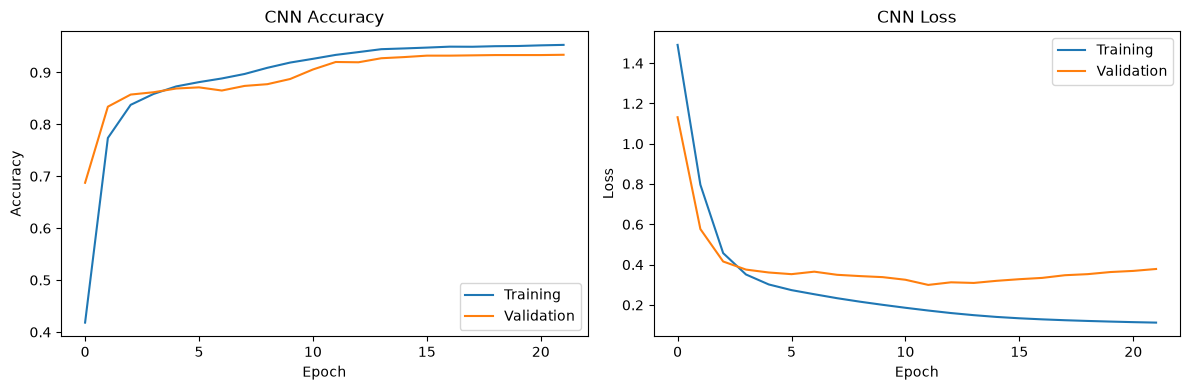

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


Test accuracy: 0.7957 (79.57%)
Test macro-F1: 0.7953
Parameters: 2,702
Batch inference time: 0.2426 seconds
Average laptop inference: 0.082 ms/window

Classification report:
                    precision    recall  f1-score   support

           WALKING     0.6705    0.8165    0.7364       496
  WALKING_UPSTAIRS     0.6302    0.6115    0.6207       471
WALKING_DOWNSTAIRS     0.9343    0.8810    0.9069       420
           SITTING     0.7766    0.7576    0.7670       491
          STANDING     0.7953    0.7011    0.7453       532
            LAYING     0.9908    1.0000    0.9954       537

          accuracy                         0.7957      2947
         macro avg     0.7996    0.7946    0.7953      2947
      weighted avg     0.8002    0.7957    0.7961      2947



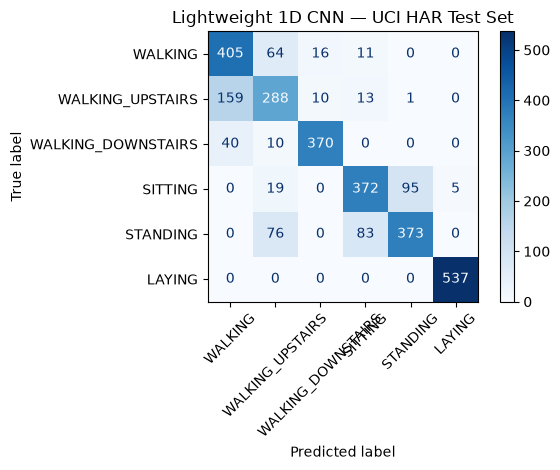

In [9]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import time

start = time.perf_counter()
test_probabilities = model.predict(
    X_test_norm,
    batch_size=64,
    verbose=0,
)
test_inference_s = time.perf_counter() - start

y_pred_cnn = np.argmax(test_probabilities, axis=1)

cnn_accuracy = accuracy_score(y_test, y_pred_cnn)
cnn_macro_f1 = f1_score(
    y_test, y_pred_cnn, average="macro"
)

print(f"Test accuracy: {cnn_accuracy:.4f} ({cnn_accuracy * 100:.2f}%)")
print(f"Test macro-F1: {cnn_macro_f1:.4f}")
print(f"Parameters: {model.count_params():,}")
print(f"Batch inference time: {test_inference_s:.4f} seconds")
print(
    "Average laptop inference: "
    f"{test_inference_s / len(y_test) * 1000:.3f} ms/window"
)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_cnn,
    labels=list(range(6)),
    target_names=ACTIVITIES,
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred_cnn, labels=list(range(6)))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ACTIVITIES,
).plot(cmap="Blues", xticks_rotation=45, values_format="d")

plt.title("Lightweight 1D CNN — UCI HAR Test Set")
plt.tight_layout()
plt.show()


In [10]:

MODEL_DIR = PROJECT_ROOT / "model"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "har_cnn_float32.keras"
model.save(model_path)

np.savez(
    MODEL_DIR / "normalization.npz",
    mean=axis_mean,
    std=axis_std,
)

cnn_results = pd.DataFrame([{
    "model": "Lightweight 1D CNN",
    "input": "(128, 3) normalized accelerometer",
    "accuracy": cnn_accuracy,
    "macro_f1": cnn_macro_f1,
    "parameters": model.count_params(),
    "model_size_bytes": model_path.stat().st_size,
    "laptop_inference_ms_per_window": (
        test_inference_s / len(y_test) * 1000
    ),
    "n_test_windows": len(y_test),
}])

cnn_results.to_csv(
    RESULTS_DIR / "cnn_float32_baseline.csv",
    index=False,
)

display(cnn_results)
print("Saved model:", model_path)


,model,input,accuracy,macro_f1,parameters,model_size_bytes,laptop_inference_ms_per_window,n_test_windows
0,Lightweight 1D CNN,"(128, 3) normalized accelerometer",0.795724,0.795258,2702,69995,0.082317,2947


Saved model: c:\Users\nandi\OneDrive\Desktop\tinyml-har-esp32\model\har_cnn_float32.keras


In [ ]:

import numpy as np
import pandas as pd

ACTIVITY_NAMES = [
    "WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS",
    "SITTING", "STANDING", "LAYING"
]

def extract_signal_features(X):
    features = {}

    for i, axis in enumerate(["x", "y", "z"]):
        signal = X[:, :, i]
        features[f"Mean_{axis}"] = signal.mean(axis=1)
        features[f"Std_{axis}"] = signal.std(axis=1)
        features[f"Min_{axis}"] = signal.min(axis=1)
        features[f"Max_{axis}"] = signal.max(axis=1)

    magnitude = np.linalg.norm(X, axis=2)
    mean_vector = X.mean(axis=1)

    features["Mean_magnitude"] = magnitude.mean(axis=1)
    features["Std_magnitude"] = magnitude.std(axis=1)
    features["Mean_vector_norm"] = np.linalg.norm(
        mean_vector, axis=1
    )

    return pd.DataFrame(features)


# Extract features
train_features = extract_signal_features(X_tr)
val_features = extract_signal_features(X_val)

train_features["Activity"] = [ACTIVITY_NAMES[i] for i in y_tr]
val_features["Activity"] = [ACTIVITY_NAMES[i] for i in y_val]


def compare_sitting_standing(df, split_name):
    sitting = df[df["Activity"] == "SITTING"].drop(
        columns="Activity"
    )
    standing = df[df["Activity"] == "STANDING"].drop(
        columns="Activity"
    )

    rows = []

    for feature in sitting.columns:
        s_mean = sitting[feature].mean()
        s_std = sitting[feature].std()
        st_mean = standing[feature].mean()
        st_std = standing[feature].std()

        pooled_std = np.sqrt(
            (
                (len(sitting) - 1) * sitting[feature].var()
                + (len(standing) - 1) * standing[feature].var()
            )
            / (len(sitting) + len(standing) - 2)
        )

        d = (
            (st_mean - s_mean) / pooled_std
            if pooled_std > 0 else np.nan
        )

        rows.append({
            "Feature": feature,
            "Sitting (Mean ± SD)": f"{s_mean:.4f} ± {s_std:.4f}",
            "Standing (Mean ± SD)": f"{st_mean:.4f} ± {st_std:.4f}",
            "Cohen's d": round(d, 4)
        })

    result = pd.DataFrame(rows)

    print(f"\n{'=' * 25} {split_name} {'=' * 25}")
    display(result)

    return result


# Only TWO tables
train_comparison = compare_sitting_standing(
    train_features, "TRAINING SET"
)

val_comparison = compare_sitting_standing(
    val_features, "VALIDATION SET"
)

# Export both tables into one Excel file
with pd.ExcelWriter(
    "sitting_standing_signal_analysis.xlsx"
) as writer:
    train_comparison.to_excel(
        writer, sheet_name="Training", index=False
    )
    val_comparison.to_excel(
        writer, sheet_name="Validation", index=False
    )

print("\nSaved: sitting_standing_signal_analysis.xlsx")


SITTING vs STANDING FEATURE SUMMARY

========== Train ==========


mean_x           std_x           min_x           max_x          \
            mean     std    mean     std    mean     std    mean     std   
activity                                                                   
SITTING   0.9522  0.1096  0.0052  0.0067  0.9367  0.1121  0.9673  0.1101   
STANDING  1.0000  0.0256  0.0055  0.0058  0.9826  0.0354  1.0175  0.0349   

         range_x          ...   max_z         range_z         mean_magnitude  \
            mean     std  ...    mean     std    mean     std           mean   
activity                  ...                                                  
SITTING   0.0306  0.0344  ...  0.1734  0.2264  0.0501  0.0469         1.0222   
STANDING  0.0349  0.0448  ... -0.0324  0.1639  0.0546  0.0490         1.0322   

                 std_magnitude         mean_vector_norm          
             std          mean     std             mean     std  
activity                                                         
SITTING   0.0081        0.0043  0.0035           1.0219  0.0081  
STANDING  0.0037        0.0057  0.0059           1.0320  0.0038  

[2 rows x 36 columns]


========== Validation ==========


mean_x          std_x           min_x           max_x          \
            mean     std   mean     std    mean     std    mean     std   
activity                                                                  
SITTING   0.9460  0.0831  0.005  0.0096  0.9318  0.0876  0.9598  0.0848   
STANDING  1.0063  0.0174  0.005  0.0064  0.9903  0.0306  1.0220  0.0273   

         range_x          ...   max_z         range_z         mean_magnitude  \
            mean     std  ...    mean     std    mean     std           mean   
activity                  ...                                                  
SITTING   0.0280  0.0473  ...  0.1950  0.1822  0.0436  0.0578         1.0175   
STANDING  0.0317  0.0455  ...  0.0768  0.1088  0.0406  0.0351         1.0349   

                 std_magnitude         mean_vector_norm          
             std          mean     std             mean     std  
activity                                                         
SITTING   0.0080        0.0039  0.0051           1.0171  0.0083  
STANDING  0.0044        0.0050  0.0062           1.0347  0.0043  

[2 rows x 36 columns]


========== EFFECT SIZE: STANDING vs SITTING ==========

Train


,Mean difference,Cohen's d,Absolute effect
min_y,-0.2821,-1.7933,1.7933
mean_y,-0.2756,-1.7931,1.7931
max_y,-0.2686,-1.7322,1.7322
mean_magnitude,0.0100,1.6130,1.6130
mean_vector_norm,0.0101,1.6001,1.6001
mean_z,-0.2079,-1.0561,1.0561
min_z,-0.2104,-1.0548,1.0548
max_z,-0.2059,-1.0463,1.0463
max_x,0.0502,0.6224,0.6224
mean_x,0.0478,0.6085,0.6085



Validation


,Mean difference,Cohen's d,Absolute effect
mean_y,-0.4109,-3.5642,3.5642
max_y,-0.4056,-3.5177,3.5177
min_y,-0.4153,-3.4247,3.4247
mean_magnitude,0.0174,2.7415,2.7415
mean_vector_norm,0.0176,2.7009,2.7009
mean_x,0.0603,1.0259,1.0259
max_x,0.0623,1.0073,1.0073
min_x,0.0586,0.9092,0.9092
max_z,-0.1181,-0.7958,0.7958
mean_z,-0.1170,-0.7840,0.7840
